# 🏦 CodeAlpha Internship — Task 1: Credit Scoring Model

**Intern:** Hammad Ahmed  
**Organisation:** CodeAlpha  
**Dataset:** German Credit Risk Dataset (Kaggle — UCI ML Repository)  
**Objective:** Predict whether a loan applicant is a **Good** or **Bad** credit risk.

---
### 📋 Pipeline Overview
1. Install & Import Libraries  
2. Load Dataset  
3. Exploratory Data Analysis (EDA)  
4. Preprocessing & Encoding  
5. Feature Engineering  
6. Train-Test Split & Scaling  
7. Model Training  
8. Model Evaluation  
9. Model Comparison Charts  
10. Feature Importance  
11. Final Summary  


In [1]:
# Install required libraries 
import sys
!{sys.executable} -m pip install pandas numpy scikit-learn matplotlib seaborn --quiet


In [2]:
# ── Imports & Global Settings ─────────────────────────────────
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# ── Plot style ────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi'       : 120,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'font.family'      : 'DejaVu Sans',
})
PALETTE = ['#2196F3', '#4CAF50', '#FF5722']

# ── Create outputs folder ─────────────────────────────────────
os.makedirs('outputs', exist_ok=True)

print(" All libraries imported successfully.")
print(f"   pandas  : {pd.__version__}")
print(f"   numpy   : {np.__version__}")


 All libraries imported successfully.
   pandas  : 2.3.3
   numpy   : 2.4.4


---
## 📂 Section 2 — Data Loading

> **Download** `german_credit_data.csv` from  
> [Kaggle — German Credit Risk](https://www.kaggle.com/datasets/uciml/german-credit)  
> and place it in the **same folder** as this notebook.


In [3]:
# ── Load Dataset ──────────────────────────────────────────────
DATA_PATH = "german_credit_data.csv"   # Must be in the same folder as this notebook

df = pd.read_csv(DATA_PATH)

# ── Normalise column names (strip spaces, title-case) ─────────
df.columns = df.columns.str.strip()

# Drop unnamed index column if present (common in Kaggle CSVs)
unnamed = [c for c in df.columns if 'Unnamed' in c]
if unnamed:
    df.drop(columns=unnamed, inplace=True)
    print(f"  Dropped unnamed columns: {unnamed}")

# ── Rename target column to 'Risk' regardless of source format ─
rename_map = {'risk': 'Risk', 'Creditability': 'Risk', 'default': 'Risk'}
df.rename(columns=rename_map, inplace=True)

print(f" Dataset loaded  →  {df.shape[0]} rows × {df.shape[1]} columns")
print(f"   Columns: {df.columns.tolist()}")
df.head()


  Dropped unnamed columns: ['Unnamed: 0']
 Dataset loaded  →  1000 rows × 10 columns
   Columns: ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


---
## 🔍 Section 3 — Exploratory Data Analysis (EDA)

In [4]:
# ── Data Types & Missing Values ───────────────────────────────
print("=" * 55)
print("  DATA INFO")
print("=" * 55)
print(df.info())

print("\n── Missing Values ──────────────────────────────────────")
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df  = pd.DataFrame({'Count': missing, 'Percent (%)': missing_pct})
display(missing_df[missing_df['Count'] > 0])


  DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Risk              1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB
None

── Missing Values ──────────────────────────────────────


,Count,Percent (%)
Saving accounts,183,18.3
Checking account,394,39.4


In [5]:
# ── Descriptive Statistics ────────────────────────────────────
display(df.describe())


,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


Target class counts:
Risk
good    700
bad     300
Name: count, dtype: int64


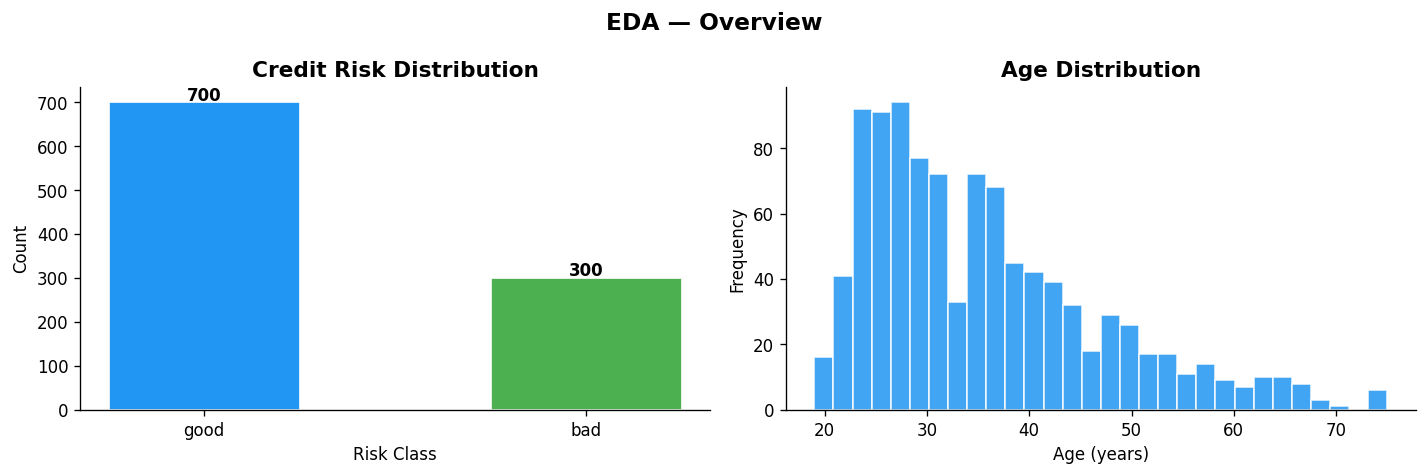

 Saved → outputs/eda_overview.png


In [6]:
# ── Target Variable Distribution ─────────────────────────────
print("Target class counts:")
print(df['Risk'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1 — Target bar chart
risk_counts = df['Risk'].value_counts()
bars = axes[0].bar(risk_counts.index, risk_counts.values,
                   color=list(PALETTE[:2]), edgecolor='white', width=0.5)
axes[0].set_title('Credit Risk Distribution', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Risk Class')
axes[0].set_ylabel('Count')
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 5,
                 int(bar.get_height()),
                 ha='center', fontweight='bold')

# Plot 2 — Age histogram
axes[1].hist(df['Age'], bins=30, color=PALETTE[0], edgecolor='white', alpha=0.85)
axes[1].set_title('Age Distribution', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Age (years)')
axes[1].set_ylabel('Frequency')

plt.suptitle('EDA — Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("outputs/eda_overview.png", bbox_inches='tight')
plt.show()
print(" Saved → outputs/eda_overview.png")


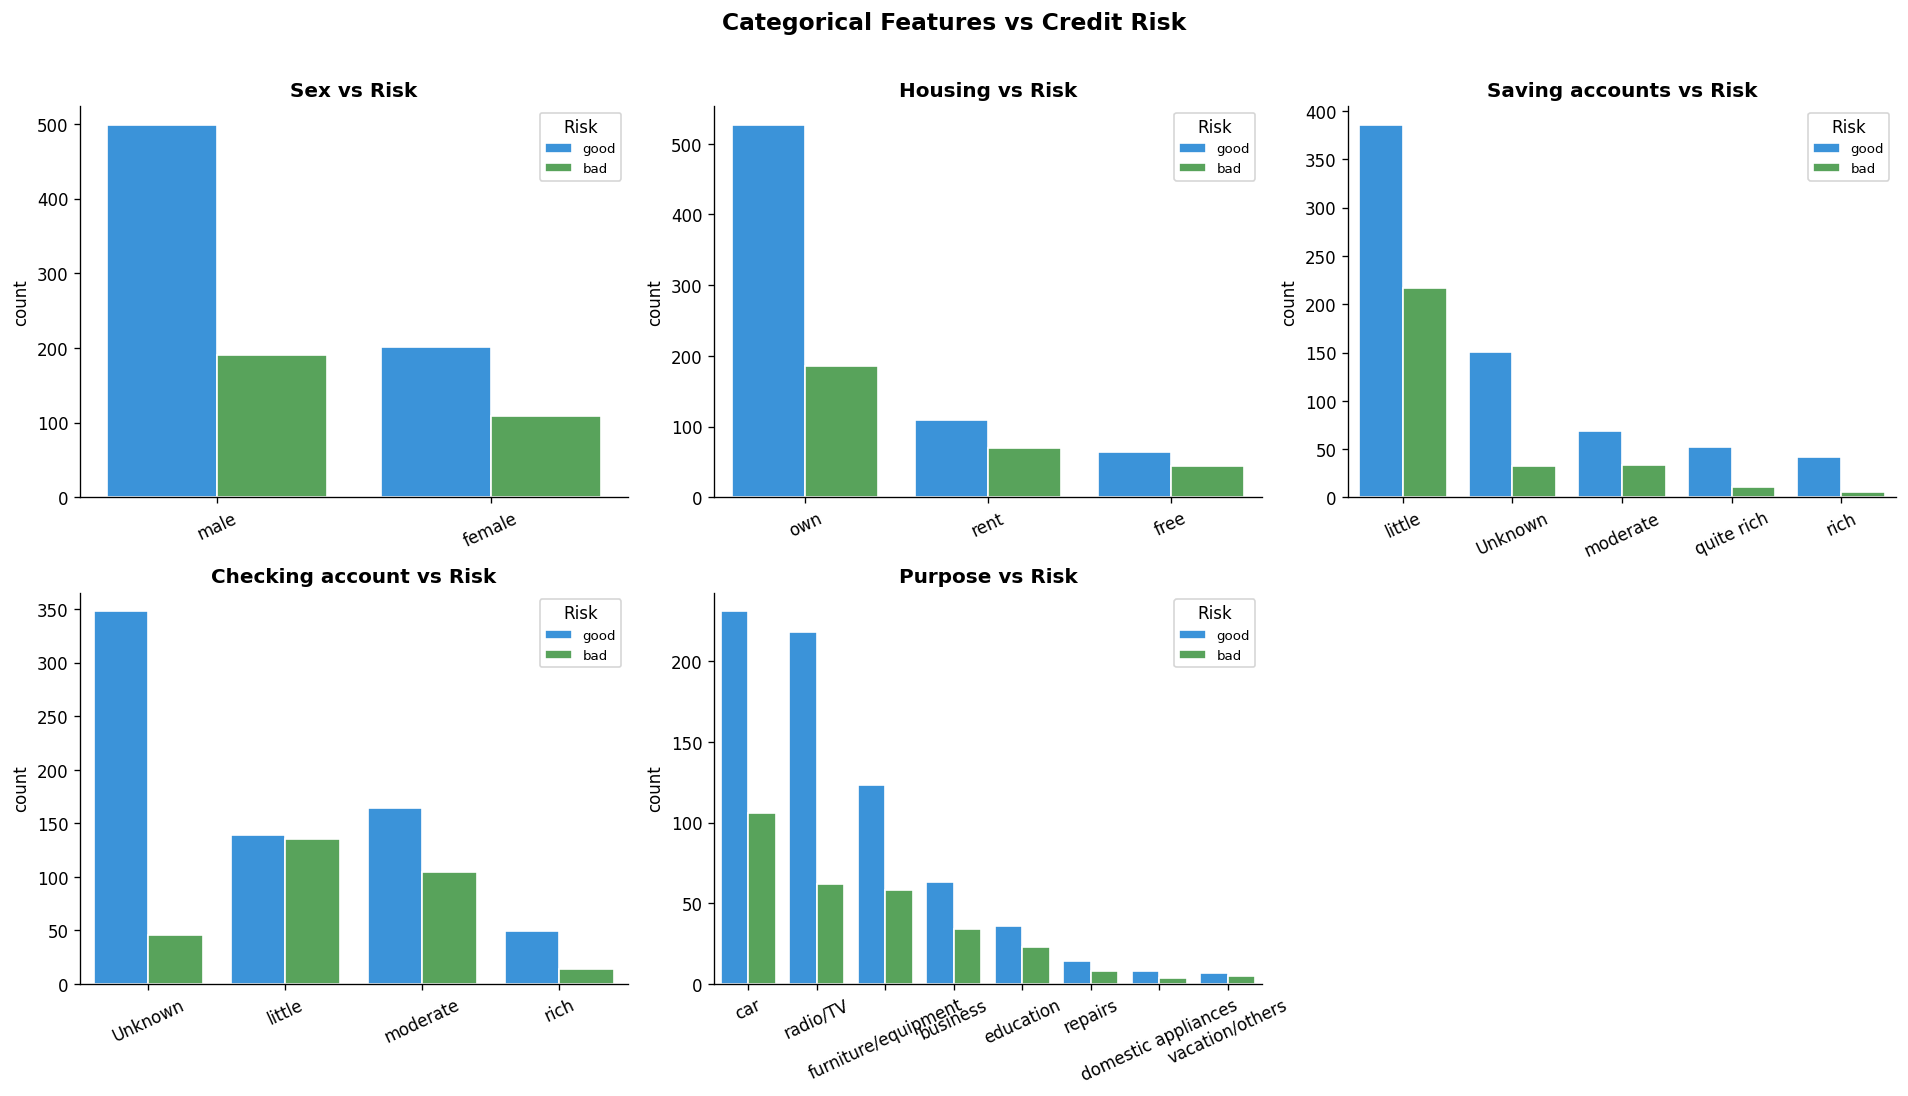

 Saved → outputs/eda_categorical.png


In [7]:
# ── Categorical Features vs Risk ─────────────────────────────
cat_cols = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
cat_cols = [c for c in cat_cols if c in df.columns]   # Keep only existing columns

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    plot_data = df[[col, 'Risk']].copy()
    plot_data[col] = plot_data[col].fillna('Unknown')
    order = plot_data[col].value_counts().index

    sns.countplot(data=plot_data, x=col, hue='Risk', ax=axes[idx],
                  order=order, palette=PALETTE[:2], edgecolor='white')
    axes[idx].set_title(f'{col} vs Risk', fontweight='bold')
    axes[idx].tick_params(axis='x', rotation=25)
    axes[idx].set_xlabel('')
    axes[idx].legend(title='Risk', fontsize=8)

# Hide unused subplots
for idx in range(len(cat_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Categorical Features vs Credit Risk',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("outputs/eda_categorical.png", bbox_inches='tight')
plt.show()
print(" Saved → outputs/eda_categorical.png")


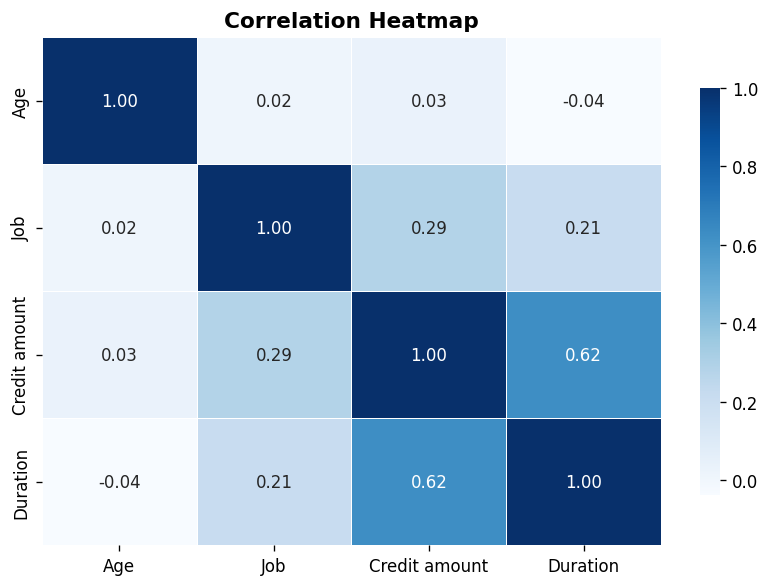

 Saved → outputs/eda_correlation.png


In [8]:
# ── Correlation Heatmap (Numerical Features) ─────────────────
num_df = df.select_dtypes(include='number')

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f',
            cmap='Blues', linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig("outputs/eda_correlation.png", bbox_inches='tight')
plt.show()
print(" Saved → outputs/eda_correlation.png")


---
## ⚙️ Section 4 — Preprocessing & Encoding

| Step | Column(s) | Technique |
|------|-----------|-----------|
| Missing values | `Saving accounts`, `Checking account` | Fill with `'unknown'` |
| Binary encoding | `Sex` | `LabelEncoder` |
| One-Hot encoding | `Housing`, `Saving accounts`, `Checking account`, `Purpose` | `pd.get_dummies` |
| Target encoding | `Risk` | `good → 0`, `bad → 1` |


In [9]:
# ── Step 4a: Fill missing categorical values ──────────────────
df_proc = df.copy()

for col in ['Saving accounts', 'Checking account']:
    if col in df_proc.columns:
        df_proc[col] = df_proc[col].fillna('unknown')

print(f"Missing values after imputation: {df_proc.isnull().sum().sum()}")


Missing values after imputation: 0


In [10]:
# ── Step 4b: Encode Target Variable (good=0, bad=1) ──────────
df_proc['Risk'] = (df_proc['Risk'].astype(str).str.strip().str.lower() == 'bad').astype(int)
print("Target encoding:  good=0  |  bad=1")
print(df_proc['Risk'].value_counts())


Target encoding:  good=0  |  bad=1
Risk
0    700
1    300
Name: count, dtype: int64


In [11]:
# ── Step 4c: Label-Encode 'Sex' ──────────────────────────────
le = LabelEncoder()
df_proc['Sex'] = le.fit_transform(df_proc['Sex'].astype(str))
print(f"Sex classes: {le.classes_}  →  {le.transform(le.classes_)}")


Sex classes: ['female' 'male']  →  [0 1]


In [12]:
# ── Step 4d: One-Hot Encode Nominal Columns ───────────────────
ohe_cols = ['Housing', 'Saving accounts', 'Checking account', 'Purpose']
ohe_cols = [c for c in ohe_cols if c in df_proc.columns]  # Only encode existing columns

df_proc = pd.get_dummies(df_proc, columns=ohe_cols, drop_first=True)

print(f"Shape after encoding: {df_proc.shape}")
print(f"Columns: {df_proc.columns.tolist()}")


Shape after encoding: (1000, 22)
Columns: ['Age', 'Sex', 'Job', 'Credit amount', 'Duration', 'Risk', 'Housing_own', 'Housing_rent', 'Saving accounts_moderate', 'Saving accounts_quite rich', 'Saving accounts_rich', 'Saving accounts_unknown', 'Checking account_moderate', 'Checking account_rich', 'Checking account_unknown', 'Purpose_car', 'Purpose_domestic appliances', 'Purpose_education', 'Purpose_furniture/equipment', 'Purpose_radio/TV', 'Purpose_repairs', 'Purpose_vacation/others']


---
## 🛠️ Section 5 — Feature Engineering

| Feature | Formula | Business Rationale |
|---------|---------|-------------------|
| `Debt_to_Duration` | `Credit Amount ÷ Duration` | Monthly repayment burden — higher = more financial strain |
| `Credit_to_Age` | `Credit Amount ÷ Age` | Loan size vs life-stage capacity — young + big loan = higher risk |


In [13]:
# ── Engineered Feature 1: Debt-to-Duration ───────────────────
df_proc['Debt_to_Duration'] = df_proc['Credit amount'] / (df_proc['Duration'] + 1e-6)
print("Feature 1 — Debt_to_Duration = Credit amount / Duration")
print(f"   Min: {df_proc['Debt_to_Duration'].min():.2f} | Max: {df_proc['Debt_to_Duration'].max():.2f} | Mean: {df_proc['Debt_to_Duration'].mean():.2f}")


Feature 1 — Debt_to_Duration = Credit amount / Duration
   Min: 24.06 | Max: 2482.67 | Mean: 167.69


In [14]:
# ── Engineered Feature 2: Credit-to-Age ──────────────────────
df_proc['Credit_to_Age'] = df_proc['Credit amount'] / (df_proc['Age'] + 1e-6)
print("Feature 2 — Credit_to_Age = Credit amount / Age")
print(f"   Min: {df_proc['Credit_to_Age'].min():.2f} | Max: {df_proc['Credit_to_Age'].max():.2f} | Mean: {df_proc['Credit_to_Age'].mean():.2f}")


Feature 2 — Credit_to_Age = Credit amount / Age
   Min: 6.10 | Max: 745.38 | Mean: 99.50


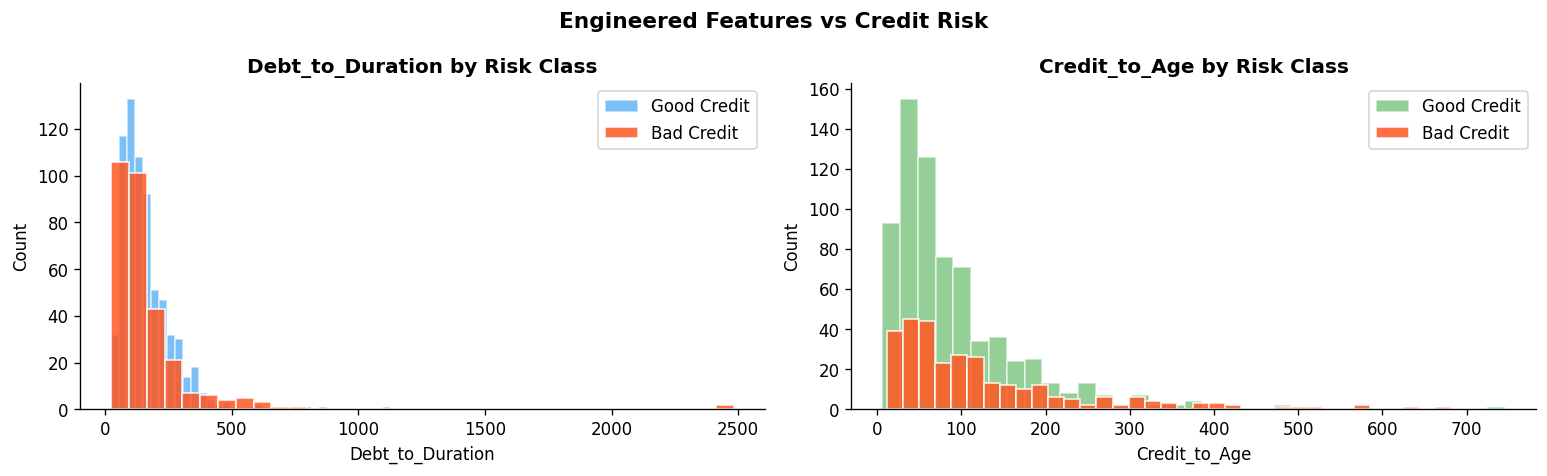

 Saved → outputs/engineered_features.png


In [15]:
# ── Visualise Engineered Features by Risk Class ───────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

feature_pairs = [
    ('Debt_to_Duration', PALETTE[0], PALETTE[2]),
    ('Credit_to_Age',    PALETTE[1], PALETTE[2]),
]

for ax, (feat, c_good, c_bad) in zip(axes, feature_pairs):
    ax.hist(df_proc.loc[df_proc['Risk'] == 0, feat],
            bins=35, alpha=0.60, label='Good Credit', color=c_good, edgecolor='white')
    ax.hist(df_proc.loc[df_proc['Risk'] == 1, feat],
            bins=35, alpha=0.85, label='Bad Credit',  color=c_bad,  edgecolor='white')
    ax.set_title(f'{feat} by Risk Class', fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Count')
    ax.legend()

plt.suptitle('Engineered Features vs Credit Risk', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("outputs/engineered_features.png", bbox_inches='tight')
plt.show()
print(" Saved → outputs/engineered_features.png")


---
## ✂️ Section 6 — Train-Test Split & Feature Scaling

In [16]:
# ── 80/20 Stratified Train-Test Split ────────────────────────
RANDOM_STATE = 42
TEST_SIZE     = 0.20

X = df_proc.drop(columns=['Risk'])
y = df_proc['Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Training samples : {X_train.shape[0]}  ({(1-TEST_SIZE)*100:.0f}%)")
print(f"Testing  samples : {X_test.shape[0]}  ({TEST_SIZE*100:.0f}%)")
print(f"Total features   : {X_train.shape[1]}")
print(f"Train class dist : {y_train.value_counts().to_dict()}")
print(f"Test  class dist : {y_test.value_counts().to_dict()}")


Training samples : 800  (80%)
Testing  samples : 200  (20%)
Total features   : 23
Train class dist : {0: 560, 1: 240}
Test  class dist : {0: 140, 1: 60}


In [17]:
# ── StandardScaler (fit on train only — no data leakage) ──────
SCALE_COLS = ['Age', 'Credit amount', 'Duration', 'Debt_to_Duration', 'Credit_to_Age']
SCALE_COLS = [c for c in SCALE_COLS if c in X_train.columns]

# Reset index to avoid index-alignment issues with loc assignment
X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

scaler = StandardScaler()
X_train[SCALE_COLS] = scaler.fit_transform(X_train[SCALE_COLS])
X_test[SCALE_COLS]  = scaler.transform(X_test[SCALE_COLS])

print(f" StandardScaler applied to: {SCALE_COLS}")
print("   (fit on TRAIN only — test set transformed, not fitted)")


 StandardScaler applied to: ['Age', 'Credit amount', 'Duration', 'Debt_to_Duration', 'Credit_to_Age']
   (fit on TRAIN only — test set transformed, not fitted)


---
## 🤖 Section 7 — Model Training

| Model | Role |
|-------|------|
| **Logistic Regression** | Linear baseline; interpretable |
| **Decision Tree** | Non-linear rule-based splits |
| **Random Forest** | Ensemble; typically strongest |

`class_weight='balanced'` corrects for the 70/30 class imbalance.


In [18]:
# ── Define Models ─────────────────────────────────────────────
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=10,
        random_state=RANDOM_STATE, class_weight='balanced'
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=5,
        random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1
    ),
}
print("Models defined:", list(models.keys()))


Models defined: ['Logistic Regression', 'Decision Tree', 'Random Forest']


In [19]:
# ── Train All Models ──────────────────────────────────────────
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"   {name:25s} trained.")

print("\n All 3 models trained successfully.")


   Logistic Regression       trained.
   Decision Tree             trained.
   Random Forest             trained.

 All 3 models trained successfully.


---
## 📊 Section 8 — Model Evaluation

For each model:
- **Confusion Matrix** — True/False Positives & Negatives  
- **Classification Report** — Precision, Recall, F1 per class  
- **ROC-AUC Score** — overall discriminative power  


  MODEL: Logistic Regression
ROC-AUC : 0.7454
              precision    recall  f1-score   support

 Good Credit       0.86      0.71      0.78       140
  Bad Credit       0.52      0.73      0.61        60

    accuracy                           0.71       200
   macro avg       0.69      0.72      0.69       200
weighted avg       0.76      0.71      0.73       200



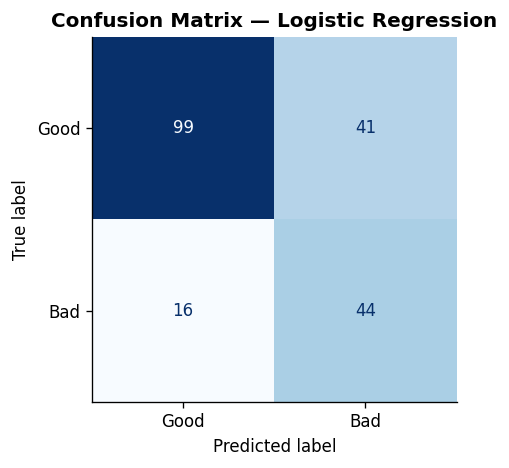

In [20]:
# ── Evaluate: Logistic Regression ─────────────────────────────
results = {}   # Will be populated for all 3 models

name  = "Logistic Regression"
model = trained_models[name]

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)
report  = classification_report(y_test, y_pred, output_dict=True)
cm      = confusion_matrix(y_test, y_pred)

results[name] = {
    'Accuracy'      : report['accuracy'],
    'Precision(Bad)': report['1']['precision'],
    'Recall(Bad)'   : report['1']['recall'],
    'F1(Bad)'       : report['1']['f1-score'],
    'ROC-AUC'       : roc_auc,
}

print(f"{'='*55}\n  MODEL: {name}\n{'='*55}")
print(f"ROC-AUC : {roc_auc:.4f}")
print(classification_report(y_test, y_pred, target_names=['Good Credit', 'Bad Credit']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Good', 'Bad']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Confusion Matrix — {name}', fontweight='bold')
plt.tight_layout()
plt.savefig(f"outputs/cm_logistic_regression.png", bbox_inches='tight')
plt.show()


  MODEL: Decision Tree
ROC-AUC : 0.6867
              precision    recall  f1-score   support

 Good Credit       0.82      0.57      0.68       140
  Bad Credit       0.42      0.72      0.53        60

    accuracy                           0.61       200
   macro avg       0.62      0.64      0.60       200
weighted avg       0.70      0.61      0.63       200



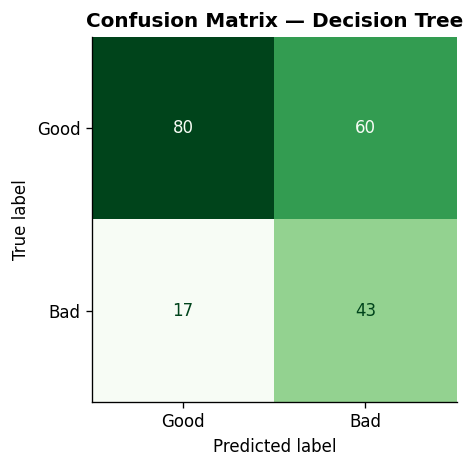

In [21]:
# ── Evaluate: Decision Tree ───────────────────────────────────
name  = "Decision Tree"
model = trained_models[name]

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)
report  = classification_report(y_test, y_pred, output_dict=True)
cm      = confusion_matrix(y_test, y_pred)

results[name] = {
    'Accuracy'      : report['accuracy'],
    'Precision(Bad)': report['1']['precision'],
    'Recall(Bad)'   : report['1']['recall'],
    'F1(Bad)'       : report['1']['f1-score'],
    'ROC-AUC'       : roc_auc,
}

print(f"{'='*55}\n  MODEL: {name}\n{'='*55}")
print(f"ROC-AUC : {roc_auc:.4f}")
print(classification_report(y_test, y_pred, target_names=['Good Credit', 'Bad Credit']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Good', 'Bad']).plot(ax=ax, colorbar=False, cmap='Greens')
ax.set_title(f'Confusion Matrix — {name}', fontweight='bold')
plt.tight_layout()
plt.savefig(f"outputs/cm_decision_tree.png", bbox_inches='tight')
plt.show()


  MODEL: Random Forest
ROC-AUC : 0.7873
              precision    recall  f1-score   support

 Good Credit       0.85      0.72      0.78       140
  Bad Credit       0.52      0.70      0.60        60

    accuracy                           0.71       200
   macro avg       0.68      0.71      0.69       200
weighted avg       0.75      0.71      0.72       200



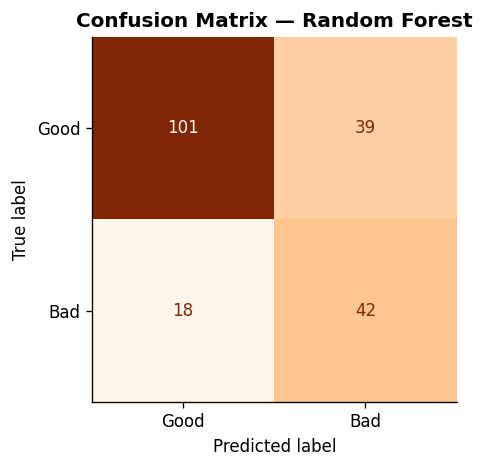


All 3 models evaluated.


In [22]:
# ── Evaluate: Random Forest ───────────────────────────────────
name  = "Random Forest"
model = trained_models[name]

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)
report  = classification_report(y_test, y_pred, output_dict=True)
cm      = confusion_matrix(y_test, y_pred)

results[name] = {
    'Accuracy'      : report['accuracy'],
    'Precision(Bad)': report['1']['precision'],
    'Recall(Bad)'   : report['1']['recall'],
    'F1(Bad)'       : report['1']['f1-score'],
    'ROC-AUC'       : roc_auc,
}

print(f"{'='*55}\n  MODEL: {name}\n{'='*55}")
print(f"ROC-AUC : {roc_auc:.4f}")
print(classification_report(y_test, y_pred, target_names=['Good Credit', 'Bad Credit']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Good', 'Bad']).plot(ax=ax, colorbar=False, cmap='Oranges')
ax.set_title(f'Confusion Matrix — {name}', fontweight='bold')
plt.tight_layout()
plt.savefig(f"outputs/cm_random_forest.png", bbox_inches='tight')
plt.show()

print("\nAll 3 models evaluated.")


---
## 📈 Section 9 — Model Comparison Charts

In [23]:
# ── Build Results Summary Table ───────────────────────────────
results_df = (
    pd.DataFrame(results).T
      .reset_index()
      .rename(columns={'index': 'Model'})
      .sort_values('ROC-AUC', ascending=False)
      .reset_index(drop=True)
)

# Convert metric columns to float (may come in as object after dict construction)
metric_cols = ['Accuracy', 'Precision(Bad)', 'Recall(Bad)', 'F1(Bad)', 'ROC-AUC']
results_df[metric_cols] = results_df[metric_cols].astype(float)

print("── Summary Results Table ──────────────────────────────")
display(results_df.round(4))


── Summary Results Table ──────────────────────────────


,Model,Accuracy,Precision(Bad),Recall(Bad),F1(Bad),ROC-AUC
0,Random Forest,0.715,0.5185,0.7000,0.5957,0.7873
1,Logistic Regression,0.715,0.5176,0.7333,0.6069,0.7454
2,Decision Tree,0.615,0.4175,0.7167,0.5276,0.6867


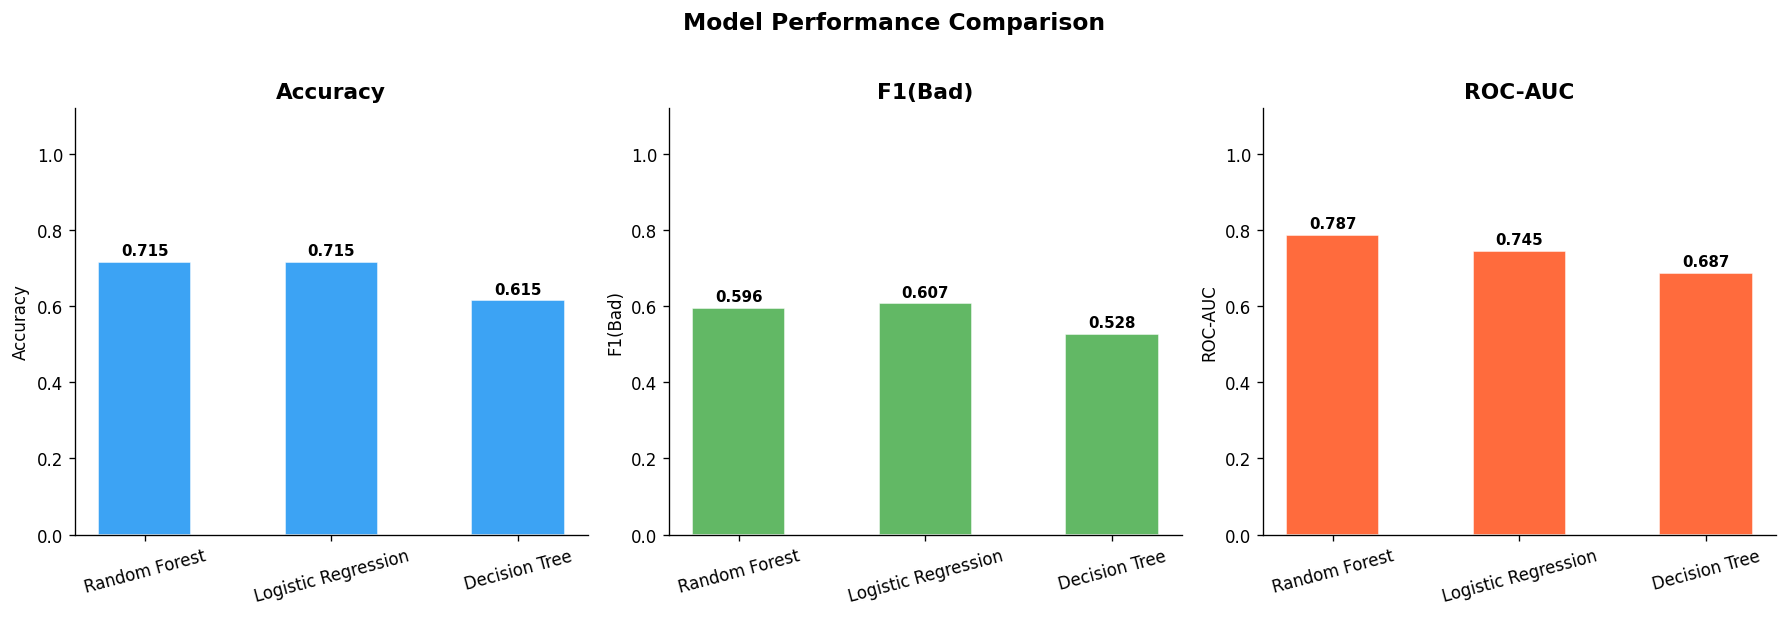

 Saved → outputs/model_comparison.png


In [24]:
# ── Comparison Bar Charts (Accuracy / F1 / ROC-AUC) ──────────
metrics    = ['Accuracy', 'F1(Bad)', 'ROC-AUC']
bar_colors = PALETTE

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric, color in zip(axes, metrics, bar_colors):
    bars = ax.bar(results_df['Model'], results_df[metric],
                  color=color, edgecolor='white', width=0.5, alpha=0.88)
    ax.set_ylim(0, 1.12)
    ax.set_title(metric, fontweight='bold', fontsize=13)
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=15)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., h + 0.01,
                f'{h:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", bbox_inches='tight')
plt.show()
print(" Saved → outputs/model_comparison.png")


---
## 🌲 Section 10 — Feature Importance (Random Forest)

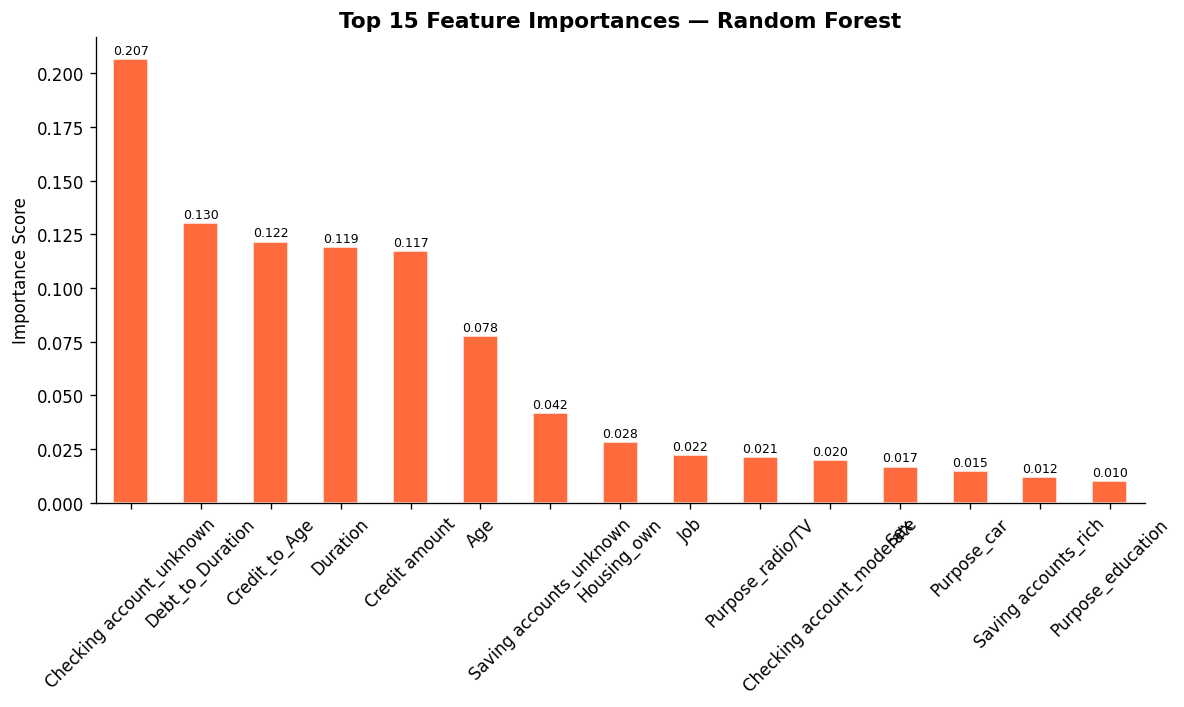

Top 5 features:
Checking account_unknown    0.206600
Debt_to_Duration            0.130149
Credit_to_Age               0.121628
Duration                    0.119093
Credit amount               0.117277


In [25]:
# ── Random Forest Feature Importance ─────────────────────────
rf_model = trained_models['Random Forest']

feat_imp = (
    pd.Series(rf_model.feature_importances_, index=X.columns)
      .sort_values(ascending=False)
      .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.plot(kind='bar', ax=ax, color=PALETTE[2], edgecolor='white', alpha=0.88)
ax.set_title('Top 15 Feature Importances — Random Forest',
             fontweight='bold', fontsize=13)
ax.set_ylabel('Importance Score')
ax.tick_params(axis='x', rotation=45)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.001,
            f'{bar.get_height():.3f}',
            ha='center', va='bottom', fontsize=7.5)

plt.tight_layout()
plt.savefig("outputs/feature_importance.png", bbox_inches='tight')
plt.show()
print("Top 5 features:")
print(feat_imp.head().to_string())


---
## 🏁 Section 11 — Final Summary

In [ ]:
# ── Final Results Summary ─────────────────────────────────────
print("=" * 58)
print("   FINAL MODEL COMPARISON SUMMARY")
print("=" * 58)
display(results_df.round(4))

best = results_df.iloc[0]
print(f"\n   Best Model  : {best['Model']}")
print(f"     ROC-AUC    : {best['ROC-AUC']:.4f}")
print(f"     F1 (Bad)   : {best['F1(Bad)']:.4f}")
print(f"     Accuracy   : {best['Accuracy']:.4f}")
print(f"\n   All output plots saved to: outputs/")
print("\n" + "=" * 58)
print("   CodeAlpha Internship — Task 1 Complete ")
print("=" * 58)


   FINAL MODEL COMPARISON SUMMARY


,Model,Accuracy,Precision(Bad),Recall(Bad),F1(Bad),ROC-AUC
0,Random Forest,0.715,0.5185,0.7000,0.5957,0.7873
1,Logistic Regression,0.715,0.5176,0.7333,0.6069,0.7454
2,Decision Tree,0.615,0.4175,0.7167,0.5276,0.6867



   Best Model  : Random Forest
     ROC-AUC    : 0.7873
     F1 (Bad)   : 0.5957
     Accuracy   : 0.7150

   All output plots saved to: outputs/

   CodeAlpha Internship — Task 1 Complete 
